<a href="https://colab.research.google.com/github/IvMatic/fraud-ring-detection-ml/blob/main/notebooks/3_anomaly_simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Experiment 02 — Harder Anomaly Detection

## Research Question
Can Isolation Forest detect subtle anomalies when
feature distributions overlap with normal behavior?

## Hypothesis
Isolation Forest will achieve lower recall on subtle
anomalies compared with extreme anomalies.

## Methodology
Generate a new synthetic dataset containing normal
accounts, extreme anomalies, and subtle anomalies.

Evaluate the model separately for each anomaly type.


In [1]:

from google.colab import drive
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

drive.mount("/content/drive")

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/fraud-ring-detection-ml"
)

RAW_DATA_PATH = PROJECT_ROOT / "data/raw"
RAW_DATA_PATH.mkdir(parents=True, exist_ok=True)

rng = np.random.default_rng(42)

# Normal accounts
normal = pd.DataFrame({
    "num_devices": rng.poisson(2, 940),
    "num_transactions_24h": rng.poisson(8, 940),
    "connected_accounts": rng.poisson(3, 940),
    "anomaly_type": "normal"
})

# Extreme anomalies
extreme = pd.DataFrame({
    "num_devices": rng.integers(8, 20, 30),
    "num_transactions_24h": rng.integers(50, 150, 30),
    "connected_accounts": rng.integers(20, 60, 30),
    "anomaly_type": "extreme"
})

# Subtle anomalies
subtle = pd.DataFrame({
    "num_devices": rng.integers(3, 7, 30),
    "num_transactions_24h": rng.integers(10, 25, 30),
    "connected_accounts": rng.integers(4, 12, 30),
    "anomaly_type": "subtle"
})

df_v2 = pd.concat(
    [normal, extreme, subtle],
    ignore_index=True
)

df_v2 = df_v2.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

df_v2.insert(
    0,
    "account_id",
    [f"ACC_{i:05d}" for i in range(1, len(df_v2) + 1)]
)

df_v2["is_synthetic_anomaly"] = (
    df_v2["anomaly_type"] != "normal"
).astype(int)

display(df_v2.head())

print("Dataset shape:", df_v2.shape)
print(df_v2["anomaly_type"].value_counts())


Mounted at /content/drive


,account_id,num_devices,num_transactions_24h,connected_accounts,anomaly_type,is_synthetic_anomaly
0,ACC_00001,0,7,5,normal,0
1,ACC_00002,0,13,4,normal,0
2,ACC_00003,3,15,7,normal,0
3,ACC_00004,2,11,2,normal,0
4,ACC_00005,2,6,4,normal,0


Dataset shape: (1000, 6)
anomaly_type
normal     940
subtle      30
extreme     30
Name: count, dtype: int64


In [2]:

DATASET_PATH = (
    RAW_DATA_PATH / "synthetic_accounts_v2.csv"
)

df_v2.to_csv(DATASET_PATH, index=False)

print("Dataset saved to:", DATASET_PATH)

print("\nAnomaly distribution:")
display(df_v2["anomaly_type"].value_counts())


Dataset saved to: /content/drive/MyDrive/fraud-ring-detection-ml/data/raw/synthetic_accounts_v2.csv

Anomaly distribution:


,count
anomaly_type,
normal,940
subtle,30
extreme,30


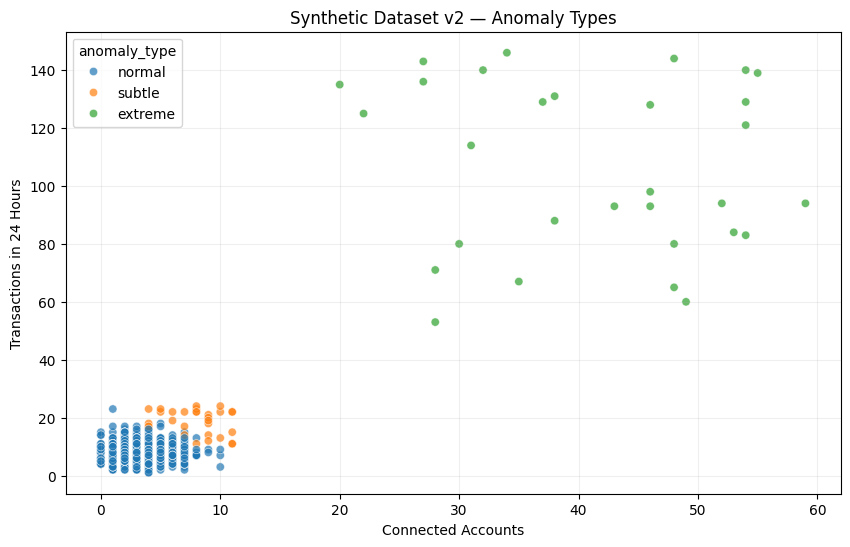

In [3]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_v2,
    x="connected_accounts",
    y="num_transactions_24h",
    hue="anomaly_type",
    hue_order=["normal", "subtle", "extreme"],
    alpha=0.7
)

plt.title("Synthetic Dataset v2 — Anomaly Types")
plt.xlabel("Connected Accounts")
plt.ylabel("Transactions in 24 Hours")
plt.grid(alpha=0.2)
plt.show()



## Isolation Forest Baseline — Dataset v2

### Research Question
How does Isolation Forest perform when anomalies
have different levels of difficulty?

### Hypothesis
Extreme anomalies will be detected more reliably
than subtle anomalies.

### Evaluation Strategy
Use a stratified train/test split.

Train Isolation Forest without anomaly labels.

Evaluate overall performance and recall separately
for extreme and subtle anomalies.


In [4]:

from sklearn.model_selection import train_test_split
from sklearn.ensemble import IsolationForest

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

FEATURES = [
    "num_devices",
    "num_transactions_24h",
    "connected_accounts"
]

X = df_v2[FEATURES]
y = df_v2["is_synthetic_anomaly"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=df_v2["anomaly_type"]
)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

print("Train anomalies:", y_train.sum())
print("Test anomalies:", y_test.sum())


Training samples: 800
Test samples: 200
Train anomalies: 48
Test anomalies: 12


In [5]:

model_v2 = IsolationForest(
    n_estimators=100,
    max_samples="auto",
    contamination=0.06,
    random_state=42
)

model_v2.fit(X_train)

y_pred = (
    model_v2.predict(X_test) == -1
).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        digits=3,
        zero_division=0
    )
)


Confusion Matrix:
[[186   2]
 [  1  11]]

Classification Report:
              precision    recall  f1-score   support

           0      0.995     0.989     0.992       188
           1      0.846     0.917     0.880        12

    accuracy                          0.985       200
   macro avg      0.920     0.953     0.936       200
weighted avg      0.986     0.985     0.985       200



In [6]:

test_results = df_v2.loc[X_test.index].copy()

test_results["predicted_anomaly"] = y_pred

results_by_type = (
    test_results
    .groupby("anomaly_type")
    .agg(
        total=("predicted_anomaly", "size"),
        detected=("predicted_anomaly", "sum")
    )
)

results_by_type["detection_rate"] = (
    results_by_type["detected"]
    / results_by_type["total"]
)

display(results_by_type)


,total,detected,detection_rate
anomaly_type,,,
extreme,6,6,1.000000
normal,188,2,0.010638
subtle,6,5,0.833333


## Error Analysis

### Objective
Investigate false positives and false negatives
to understand where Isolation Forest struggles.

### Research Questions
- Which anomalous accounts were missed?
- Why were some normal accounts flagged as anomalies?
- Do false negatives share characteristics with normal accounts?

In [7]:

# Add anomaly scores to test results
test_results["anomaly_score"] = (
    -model_v2.score_samples(X_test)
)

# False positives:
# Normal accounts predicted as anomalies
false_positives = test_results[
    (test_results["is_synthetic_anomaly"] == 0) &
    (test_results["predicted_anomaly"] == 1)
]

# False negatives:
# Anomalous accounts predicted as normal
false_negatives = test_results[
    (test_results["is_synthetic_anomaly"] == 1) &
    (test_results["predicted_anomaly"] == 0)
]

columns = [
    "account_id",
    "anomaly_type",
    "num_devices",
    "num_transactions_24h",
    "connected_accounts",
    "anomaly_score"
]

print("FALSE POSITIVES")
display(false_positives[columns])

print("\nFALSE NEGATIVES")
display(false_negatives[columns])


FALSE POSITIVES


,account_id,anomaly_type,num_devices,num_transactions_24h,connected_accounts,anomaly_score
250,ACC_00251,normal,6,3,4,0.587983
640,ACC_00641,normal,8,10,5,0.589415



FALSE NEGATIVES


,account_id,anomaly_type,num_devices,num_transactions_24h,connected_accounts,anomaly_score
618,ACC_00619,subtle,3,14,7,0.49911



## Findings and Interpretation

### 1. Experiment Objective

Investigate whether Isolation Forest can detect
different types of synthetic anomalies when
feature distributions partially overlap.

### 2. Dataset

The dataset contains 1,000 synthetic accounts:

- 940 normal accounts
- 30 extreme anomalies
- 30 subtle anomalies

Features:
- num_devices
- num_transactions_24h
- connected_accounts

### 3. Model Configuration

- Algorithm: Isolation Forest
- n_estimators: 100
- max_samples: auto
- contamination: 0.06
- random_state: 42
- Train/test split: 80/20, stratified by anomaly type

Anomaly labels were excluded from training.

### 4. Overall Test Results

| Metric | Score |
|---|---:|
| Precision | 0.846 |
| Recall | 0.917 |
| F1-score | 0.880 |
| Accuracy | 0.985 |

Confusion matrix:

| | Predicted Normal | Predicted Anomaly |
|---|---:|---:|
| Actual Normal | 186 | 2 |
| Actual Anomaly | 1 | 11 |

### 5. Detection by Anomaly Type

| Type | Total | Detected | Detection Rate |
|---|---:|---:|---:|
| Extreme | 6 | 6 | 100% |
| Subtle | 6 | 5 | 83.3% |
| Normal | 188 | 2 | 1.06% |

For normal accounts, the detection rate represents
the false positive rate.

### 6. Error Analysis

Two normal accounts were incorrectly flagged:

- ACC_00251: 6 devices, 3 transactions,
  4 connected accounts
- ACC_00641: 8 devices, 10 transactions,
  5 connected accounts

Both had unusually high device counts compared
with typical normal accounts.

One subtle anomaly was missed:

- ACC_00619: 3 devices, 14 transactions,
  7 connected accounts

This account had relatively moderate feature
values, which may have made it harder to isolate.

These explanations are hypotheses based on
observed values, not verified feature attributions.

### 7. Key Learnings

- Isolation Forest detected all extreme anomalies
  in the test set.
- Subtle anomalies were harder to detect.
- Unusual combinations of otherwise legitimate
  account behavior can produce false positives.
- Anomaly detection performance depends on
  the quality and informativeness of features.
- High overall accuracy can hide weaknesses
  when anomalies are rare.

### 8. Limitations

- The dataset is fully synthetic.
- The anomaly categories were manually defined.
- Only 12 anomalous accounts were present
  in the test set.
- The contamination parameter matched the known
  synthetic anomaly rate.
- The dataset does not contain actual graph edges.
- Results cannot be generalized to real financial
  fraud without additional evaluation.

### 9. Next Steps

1. Conduct a feature ablation study.
2. Compare Isolation Forest with other anomaly
   detection algorithms.
3. Introduce realistic financial transaction data.
4. Investigate graph-based features using Memgraph.

### Reference

Liu, F. T., Ting, K. M., & Zhou, Z.-H. (2008).
Isolation Forest.
https://doi.org/10.1109/ICDM.2008.17


## Personal Research Reflection

This experiment helped me understand that achieving good anomaly detection performance depends not only on the choice of algorithm but also on the characteristics of the dataset.

In the first experiment, Isolation Forest achieved perfect results because the synthetic anomalies were clearly separated from normal accounts.

After introducing subtle anomalies, the model started producing false positives and false negatives.

One important observation was that the missed subtle anomaly had feature values relatively close to those of normal accounts.

This suggests that detecting sophisticated fraud patterns may require additional contextual or graph-based information.

However, I cannot conclude that graph features would solve this problem without testing that hypothesis.

My next step is to investigate how removing individual features affects anomaly detection performance.